<a href="https://colab.research.google.com/github/AkramShaik-67/Deepfake_detection_using_ViT_SwinTransformer/blob/main/Deepfake_detection_using_ViT%26Swin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This cell mounts Google Drive to the Colab environment, allowing access to files stored in your Drive, including the dataset.

In [ ]:
# Import the Google Drive module for mounting
from google.colab import drive
# Mount Google Drive to access files and datasets stored there
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


This cell defines the file paths to the training, validation, and test datasets located in Google Drive. These paths will be used by the data loaders.

In [ ]:
# Define the directory paths for the training, validation, and test datasets
# These paths point to folders on Google Drive where the image data is stored
train_dir ='/content/drive/My Drive/Dataset/Train'
val_dir = '/content/drive/My Drive/Dataset/Validation'
test_dir = '/content/drive/My Drive/Dataset/Test'

This cell imports various essential Python libraries: `os` for operating system interactions, `random` for random selections, `cv2` for image processing, `numpy` for numerical operations, `matplotlib.pyplot` for plotting, and key PyTorch modules like `torch`, `torch.nn`, `torch.utils.data.DataLoader`, `torchvision.datasets`, `torchvision.transforms`, and `timm` for deep learning functionalities.

In [ ]:
# Import necessary modules and libraries for data handling and visualization
import os # For interacting with the operating system, e.g., listing directory contents
import random # For generating random numbers, useful for selecting random images
import cv2 # OpenCV library for image processing tasks (e.g., filtering)
import numpy as np # NumPy library for numerical operations, especially with arrays
import matplotlib.pyplot as plt # Matplotlib for creating static, interactive, and animated visualizations
import torch # Core PyTorch library
import torch.nn as nn # Neural network module for defining layers
from torch.utils.data import DataLoader # Utility for loading data in batches
from torchvision import datasets, transforms # Datasets and transformations for computer vision
import timm # PyTorch Image Models library

This cell checks for PyTorch installation and CUDA (GPU) availability. It prints the PyTorch version, whether a GPU is detected, and if so, the GPU's name. It also provides a reminder to enable GPU if it's not detected.

In [ ]:
# Print the installed PyTorch version to verify the environment setup
print("PyTorch version:", torch.__version__)
# Check if a CUDA-enabled GPU is available for use to leverage GPU acceleration
print("CUDA available:", torch.cuda.is_available())

# Conditional statement to inform the user about GPU status
if torch.cuda.is_available():
    # If GPU is available, print the name of the first detected GPU for confirmation
    print("GPU:", torch.cuda.get_device_name(0))
else:
    # If no GPU is found, advise the user to enable it in Colab runtime settings
    print("⚠️ GPU is not enabled. Go to Runtime → Change runtime type → GPU")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


This cell initializes the `device` variable based on whether a CUDA-enabled GPU is available. If a GPU is present, it sets the device to 'cuda'; otherwise, it defaults to 'cpu'. This ensures that PyTorch tensors and models are moved to the appropriate computing device.

In [24]:
# Define the device to be used for computations: 'cuda' if a GPU is available, otherwise 'cpu'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Print the selected device to confirm whether GPU or CPU is being utilized
print(f"Using device: {device}")

Using device: cuda


This cell re-confirms the directory paths for the training, validation, and test datasets and checks if these directories actually exist on the file system. This ensures that the data can be accessed correctly.

In [ ]:
# Check and print whether each directory path actually exists
print("Train exists:", os.path.exists(train_dir))
print("Validation exists:", os.path.exists(val_dir))
print("Test exists:", os.path.exists(test_dir))

Train exists: True
Validation exists: True
Test exists: True


This cell inspects the training directory to identify and count the number of distinct classes (subfolders). It then prints the total class count and the names of the identified classes, confirming the structure of the dataset categories.

In [ ]:
# Import the 'os' module again
import os

# List all subdirectories within the training directory, which represent the classes
classes = os.listdir(train_dir)
# Get the number of classes based on the length of the list
num_classes = len(classes)

# Display the total number of classes found
print(f'Number of Classes: {num_classes}')

# List and print the names of subfolders (classes) within the training directory
print("Train folders:", os.listdir(train_dir))
# List and print the names of subfolders (classes) within the validation directory
print("Validation folders:", os.listdir(val_dir))
# List and print the names of subfolders (classes) within the test directory
print("Test folders:", os.listdir(test_dir))

Number of Classes: 2
Train folders: ['Fake', 'Real']
Validation folders: ['Fake', 'Real']
Test folders: ['Real', 'Fake']


This cell visualizes a random image from the training dataset. It selects a random class, then a random image within that class, reads it, and displays it with its class label and shape.

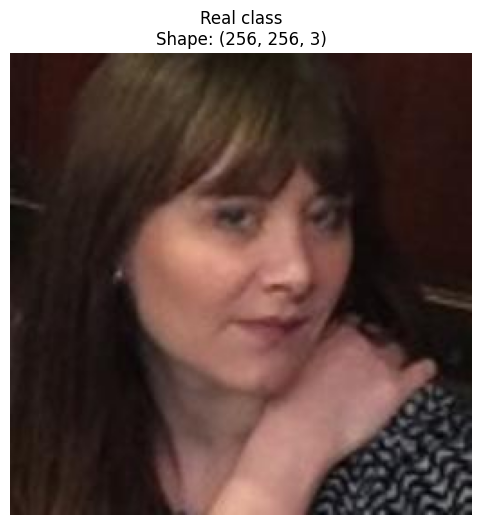

In [ ]:
# This cell is dedicated to visualizing example images from the dataset.
# Choose a random class (e.g., 'Fake' or 'Real') from the 'classes' list
random_class = random.choice(classes)

# Construct the full path to the directory of the randomly chosen class
random_class_path = os.path.join(train_dir, random_class)

# Get a list of all image file names present in that specific class directory
image_files = os.listdir(random_class_path)

# Choose a random image file name from the list of images in the chosen class
random_img_name = random.choice(image_files)

# Construct the complete file path for the randomly selected image
random_img_path = os.path.join(random_class_path, random_img_name)

# Read the image file using Matplotlib's imread function (reads as a NumPy array)
random_img = plt.imread(random_img_path)

# Create a new figure for displaying the image with a specified size
plt.figure(figsize=(6, 6))
# Display the image
plt.imshow(random_img)
# Set the title of the plot to indicate the class and image shape
plt.title(f'{random_class} class\nShape: {random_img.shape}')
# Turn off the axis ticks and labels for a cleaner image display
plt.axis('off')
# Show the plot
plt.show()

This cell sets up essential components for image data loading and preprocessing. It defines `IMG_SIZE` and `BATCH_SIZE`, creates image transformation pipelines for training (with augmentation) and validation/testing (without augmentation), constructs `ImageFolder` datasets, and finally initializes `DataLoader` objects for efficient batch processing of the training, validation, and test sets. It also prints dataset statistics.

In [ ]:
# Import DataLoader from PyTorch's data utility for efficient batch loading
from torch.utils.data import DataLoader

# Define image size and batch size for PyTorch DataLoader
IMG_SIZE = 224 # Target size (width and height) for images
BATCH_SIZE = 8 # Number of images per batch for PyTorch DataLoader

# Define transformations for the training dataset
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Resize images to the specified IMG_SIZE
    transforms.RandomHorizontalFlip(), # Randomly flip images horizontally for data augmentation
    transforms.RandomRotation(10), # Randomly rotate images by up to 10 degrees
    transforms.ColorJitter( # Randomly change brightness and contrast
        brightness=0.2, # Adjust brightness by up to 20%
        contrast=0.2 # Adjust contrast by up to 20%
    ),
    transforms.ToTensor(), # Convert images to PyTorch Tensors
    transforms.Normalize( # Normalize pixel values using mean and standard deviation
        mean=[0.485, 0.456, 0.406], # Mean values for R, G, B channels (ImageNet statistics)
        std=[0.229, 0.224, 0.225] # Standard deviation values for R, G, B channels (ImageNet statistics)
    )
])

# Define transformations for the validation and test datasets (no augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), # Resize images to the specified IMG_SIZE
    transforms.ToTensor(), # Convert images to PyTorch Tensors
    transforms.Normalize( # Normalize pixel values using mean and standard deviation
        mean=[0.485, 0.456, 0.406], # Mean values for R, G, B channels (ImageNet statistics)
        std=[0.229, 0.224, 0.225] # Standard deviation values for R, G, B channels (ImageNet statistics)
    )
])

# Create ImageFolder datasets for training, validation, and test sets
# ImageFolder expects images sorted into subfolders named after their class
train_dataset = datasets.ImageFolder(
    train_dir, # Path to the training data directory
    transform=train_transform # Apply the defined training transformations
)

val_dataset = datasets.ImageFolder(
    val_dir, # Path to the validation data directory
    transform=val_test_transform # Apply the defined validation/test transformations
)

test_dataset = datasets.ImageFolder(
    test_dir, # Path to the test data directory
    transform=val_test_transform # Apply the defined validation/test transformations
)

# Create a DataLoader for the training dataset
train_loader = DataLoader(
    train_dataset, # The dataset to load data from
    batch_size=BATCH_SIZE, # Number of samples per batch
    shuffle=True, # Shuffle the data every epoch for better training
    num_workers=2, # Number of subprocesses to use for data loading
    pin_memory=True # Copy Tensors to CUDA pinned memory before returning them
)

# Create a DataLoader for the validation dataset
val_loader = DataLoader(
    val_dataset, # The dataset to load data from
    batch_size=BATCH_SIZE, # Number of samples per batch
    shuffle=False, # No need to shuffle validation data
    num_workers=2, # Number of subprocesses for data loading
    pin_memory=True # Copy Tensors to CUDA pinned memory
)

# Create a DataLoader for the test dataset
test_loader = DataLoader(
    test_dataset, # The dataset to load data from
    batch_size=BATCH_SIZE, # Number of samples per batch
    shuffle=False, # No need to shuffle test data
    num_workers=2, # Number of subprocesses for data loading
    pin_memory=True # Copy Tensors to CUDA pinned memory
)

# Print the class names inferred by ImageFolder
print("Classes:", train_dataset.classes)
# Print the total number of images in each dataset
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

# Print the number of batches in each DataLoader
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Classes: ['Fake', 'Real']
Train images: 140022
Validation images: 39440
Test images: 10905
Train batches: 17503
Validation batches: 4930
Test batches: 1364


The previous code cell defines the image preprocessing pipeline for the dataset.

Here's a summary of the key steps:

1.  **Image Size and Batch Size Definition**: `IMG_SIZE` is set to 224x224 pixels, and `BATCH_SIZE` is 8.
2.  **Training Transformations**: A `train_transform` pipeline is created, including:
    *   Resizing images to `IMG_SIZE`.
    *   Applying data augmentation techniques: `RandomHorizontalFlip`, `RandomRotation` (by 10 degrees), and `ColorJitter` (adjusting brightness and contrast).
    *   Converting images to PyTorch Tensors (`ToTensor`).
    *   Normalizing pixel values using ImageNet's mean and standard deviation for RGB channels.
3.  **Validation/Test Transformations**: A `val_test_transform` pipeline is created for validation and testing, which includes:
    *   Resizing images to `IMG_SIZE`.
    *   Converting images to PyTorch Tensors.
    *   Normalizing pixel values using ImageNet's mean and standard deviation.
4.  **Dataset Creation**: `ImageFolder` datasets are created for the training, validation, and test directories, applying the respective transformation pipelines.
5.  **DataLoader Initialization**: `DataLoader` objects are initialized for each dataset (`train_loader`, `val_loader`, `test_loader`) to facilitate efficient batching, shuffling (for training), and multiprocessing for data loading.
6.  **Dataset Statistics**: The class names and the total number of images in each dataset (training, validation, and test) are printed, along with the number of batches in each DataLoader.

This cell applies a bilateral filter to the previously loaded random image. A bilateral filter is used for noise reduction while preserving edges. It then displays both the original and the filtered image side-by-side for a visual comparison of the filtering effect.

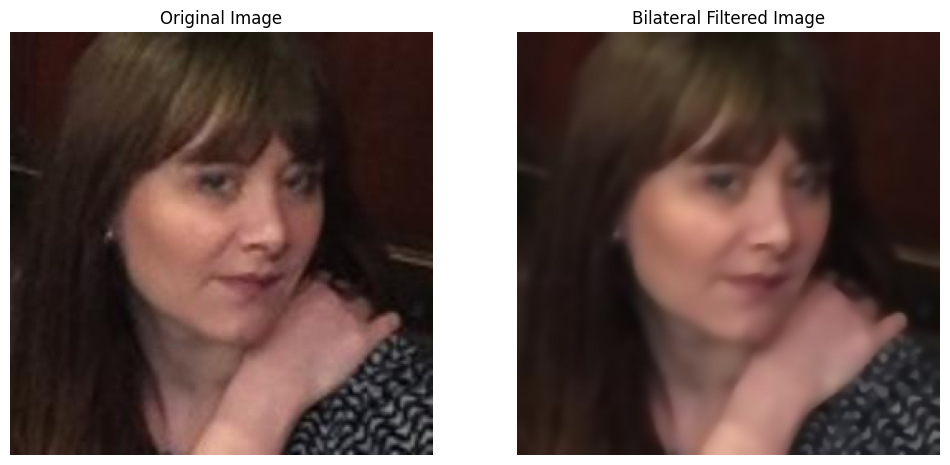

In [ ]:
# Apply a bilateral filter for noise reduction while preserving edges of the 'random_img'
# d: Diameter of each pixel neighborhood that is used during filtering. A larger value means more pixels are considered.
# sigmaColor: Filter sigma in the color space. A larger value means farther colors within the neighborhood will be mixed.
# sigmaSpace: Filter sigma in the coordinate space. A larger value means farther pixels will influence each other if their colors are close enough.
filtered_img = cv2.bilateralFilter(random_img, d=9, sigmaColor=100, sigmaSpace=100)

# Create a figure to display both the original and filtered images side-by-side
plt.figure(figsize=(12, 6))

# Create the first subplot for the original image
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.imshow(random_img) # Display the original image
plt.title('Original Image') # Set title for the original image plot
plt.axis('off') # Turn off axis ticks and labels

# Create the second subplot for the bilateral filtered image
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.imshow(filtered_img) # Display the filtered image
plt.title('Bilateral Filtered Image') # Set title for the filtered image plot
plt.axis('off') # Turn off axis ticks and labels

# Show the combined plot
plt.show()

This cell initializes a Swin Transformer model (specifically the 'tiny' variant) from the `timm` library. It loads pre-trained weights for improved performance and configures the output layer for 2 classification classes. A confirmation message indicates successful model loading.

In [ ]:
# Create a Swin Transformer model with a tiny architecture
# 'swin_tiny_patch4_window7_224': Specifies the model architecture and input resolution
# pretrained=True: Loads pre-trained weights (usually from ImageNet) for better performance and faster convergence
# num_classes=2: Adjusts the final classification layer to output 2 classes (for 'Fake'/'Real' binary classification)
model = timm.create_model(
    'swin_tiny_patch4_window7_224',
    pretrained=True,
    num_classes=2
)

# Print a success message once the Swin Transformer model is loaded to indicate readiness
print("Swin Transformer model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Swin Transformer model loaded successfully!


This cell initializes a Vision Transformer (ViT) model, utilizing the 'base' architecture with 16x16 patches and 224x224 input resolution, also from the `timm` library. It loads pre-trained weights and sets up the final layer for 2 classification classes. A message confirms its successful loading.

In [ ]:
# Create a Vision Transformer (ViT) model with a base architecture
# 'vit_base_patch16_224': Specifies the ViT base architecture with 16x16 patches and 224x224 input image resolution
# pretrained=True: Loads pre-trained weights for the ViT model, crucial for transfer learning
# num_classes=2: Adjusts the final classification layer for 2 output classes, matching our problem's requirement
vit_model = timm.create_model(
    'vit_base_patch16_224',
    pretrained=True,
    num_classes=2
)

# Print a success message once the Vision Transformer (ViT) model is loaded to confirm completion
print("Vision Transformer (ViT) model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Vision Transformer (ViT) model loaded successfully!


This cell extracts the number of output features from the penultimate layers (before the final classification heads) of both the Swin Transformer and Vision Transformer models. These feature counts are crucial for designing the subsequent hybrid classifier that combines their outputs.

In [ ]:
# Get the number of features from the Swin Transformer's head (before the classification layer)
# This information is essential for concatenating features from different models
swin_features = model.num_features
# Get the number of features from the Vision Transformer's head
vit_features = vit_model.num_features

# Print the extracted feature counts for both models to verify their dimensions
print("Swin features:", swin_features)
print("ViT features:", vit_features)

Swin features: 768
ViT features: 768


This cell defines a `hybrid_classifier` using PyTorch's `nn.Sequential`. This classifier combines features from both Swin and ViT models, passing them through two linear layers, a ReLU activation, and a dropout layer, ultimately outputting predictions for 2 classes. A success message is printed after its creation.

In [ ]:
# Import the neural network module from PyTorch for defining custom layers
import torch.nn as nn

# Define a hybrid classifier using PyTorch's Sequential container to combine layers linearly
# This classifier takes concatenated features from both Swin and ViT models as input
hybrid_classifier = nn.Sequential(
    # First linear layer: input size is the sum of Swin and ViT features (768 + 768),
    # and it reduces the dimension to 512 for subsequent processing.
    nn.Linear(768 + 768, 512),
    nn.ReLU(), # ReLU activation function to introduce non-linearity into the model
    nn.Dropout(0.3), # Dropout layer with a 30% probability of dropping neurons during training for regularization, preventing overfitting
    # Second linear layer: input size 512, output size 2 (for 2 classes: 'Fake' or 'Real')
    nn.Linear(512, 2)
)

# Print a success message once the hybrid classifier is created to confirm its construction
print("Hybrid classifier created successfully!")

Hybrid classifier created successfully!


This cell defines the `HybridSwinViT` class, a custom neural network module that combines a Swin Transformer and a Vision Transformer. It includes a `forward` method to process input images, extract features from both models, concatenate these features, and pass them through a final classifier to produce predictions.

In [ ]:
class HybridSwinViT(nn.Module):
    # Initialize the HybridSwinViT model with a Swin Transformer, a Vision Transformer, and a classifier
    def __init__(self, swin_model, vit_model, classifier):
        super().__init__() # Call the constructor of the parent class (nn.Module)
        self.swin = swin_model # Assign the Swin Transformer model
        self.vit = vit_model # Assign the Vision Transformer model
        self.classifier = classifier # Assign the final classification head

    # Define the forward pass for the HybridSwinViT model
    def forward(self, x):
        # Extract features from the Swin Transformer part of the model
        swin_features = self.swin.forward_features(x)
        # Extract features from the Vision Transformer part of the model
        vit_features = self.vit.forward_features(x)

        # If Swin features are 4-dimensional (batch, channel, height, width),
        # perform global average pooling to get 2-dimensional features (batch, channel)
        if swin_features.dim() == 4:
            swin_features = swin_features.mean(dim=(2, 3)) # Average over height and width dimensions

        # If ViT features are 3-dimensional (batch, tokens, embedding_dim),
        # take only the [CLS] token's embedding (first token) as the global representation
        if vit_features.dim() == 3:
            vit_features = vit_features[:, 0] # Select the first token (CLS token)

        # Concatenate the processed Swin and ViT features along the feature dimension (dim=1)
        combined = torch.cat(
            [swin_features, vit_features],
            dim=1
        )

        # Pass the combined features through the final hybrid classifier to get predictions
        return self.classifier(combined)

# Print a message to confirm that the HybridSwinViT class definition is ready
print("Hybrid class ready!")

Hybrid class ready!


This cell instantiates the `HybridSwinViT` model, integrating the pre-loaded Swin Transformer, Vision Transformer, and the custom hybrid classifier. The entire model is then moved to the previously defined `device` (GPU or CPU) for computation, ensuring it's ready for training or inference.

In [25]:
# Instantiate the HybridSwinViT model using the pre-loaded Swin Transformer, Vision Transformer, and hybrid classifier
hybrid_model = HybridSwinViT(
    model, # The Swin Transformer model
    vit_model, # The Vision Transformer model
    hybrid_classifier # The custom classifier that combines their features
).to(device) # Move the entire hybrid model to the specified device (GPU or CPU)

# Print a confirmation message indicating that the hybrid model is fully initialized and ready for use
print("Hybrid Swin + ViT model ready!")

Hybrid Swin + ViT model ready!


This cell performs an initial test of the instantiated `HybridSwinViT` model. It retrieves a batch of images from the `train_loader`, moves them to the appropriate device, and then passes them through the hybrid model in inference mode (without gradient calculation). Finally, it prints the shapes of the input images and the model's output, confirming the model's forward pass functionality.

In [26]:
# Get a batch of images and their corresponding labels from the training data loader
images, labels = next(iter(train_loader))

# Move the image tensor to the designated device (GPU for faster computation if available)
images = images.to(device)

# Disable gradient calculations during this inference step to save memory and computation
with torch.no_grad():
    # Pass the image batch through the hybrid model to get predictions
    output = hybrid_model(images)

# Print the shape of the input images to verify the batch dimensions (batch_size, channels, height, width)
print("Input shape:", images.shape)
# Print the shape of the model's output to verify the prediction dimensions (batch_size, num_classes)
print("Output shape:", output.shape)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 2])
